# Imports 

In [22]:
import calfem.core as cfc
import calfem.geometry as cfg
import calfem.mesh as cfm
import calfem.utils as cfu
import matplotlib.pyplot as plt
import calfem.vis_mpl as cfv
import numpy as np

# Define Global parameters

In [23]:
# Define units
H, L1, L2, R, D = 0.200, 0.300, 0.400, 0.025, 0.0875

thickness = 1.6      # Thickness of the battery prototype [m] 
                     # All matrices are propotional to this and 
                     # this is independent of coordinates and can 
                     # thus be dropped.

# Convection parameters
T_out = 285          # Hotter cooling fluid [K]
T_in = 277           # Cooler cooling fluid [K]
T0 = 293            # Ambient temperature [K]
alpha_n = 40         # Newton convection to air [1/K]
alpha_c = 120        # Newton convection to cooling channel  [1/K]

k = 80               # Thermal conductivity [J/kg/K]

density = 540        # Material Density [kg/m^3]
specific_heat = 3600 # Specific heat of material [J/kg/K]
E = 5e9              # Young's modulus [Pa]
v = 0.36             # Poisson's ratio [n.d]
alpha = 60e-6        # Expansion coefficient [1/K],

# Define Geometry 

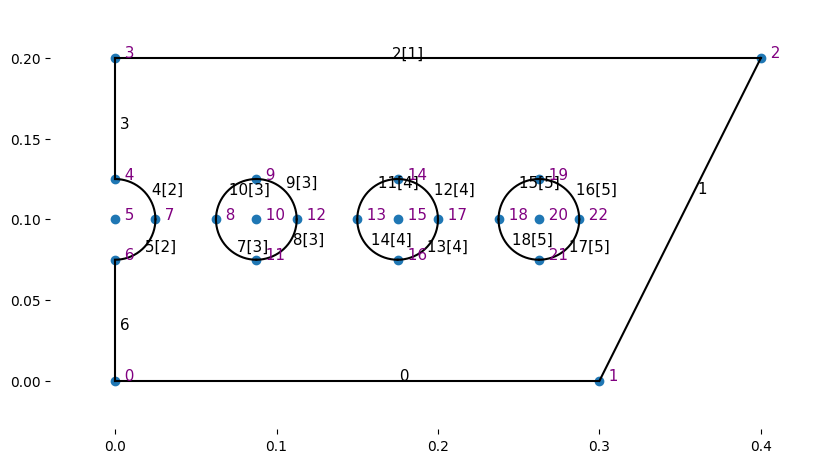

In [24]:
# Create geometry tool
g = cfg.geometry()

# Define points 
points = [
    # Points on outer parallellipiped 0, 1, 2, 3
    [0, 0], [L1, 0], [L2, H], [0, H], 
    # Points on half circle 4, 5, 6, 7                                          
    [0, H/2 + R], [0, H/2], [0, H/2 - R], [R, H/2],     
    # Points on circle center in D, H/2 8, 9, 10, 11, 12                        
    [D - R, H/2], [D, H/2 + R], [D, H/2], [D, H/2 - R], [D + R, H/2], 
     # Points on circle center in 2D, H/2 13, 14, 15, 16, 17           
    [2*D - R, H/2], [2*D, H/2 + R], [2*D, H/2], [2*D, H/2 - R], [2*D + R, H/2],
    # Points on circle center in 3D, H/2 18, 19, 20, 21, 22
    [3*D - R, H/2], [3*D, H/2 + R], [3*D, H/2], [3*D, H/2 - R], [3*D + R, H/2]  
]

# Add points in geometry tool
for index, point in enumerate(points):
    g.point(point, index)

# Markers for boundary conditions
MARKER_Q_0        = 0
MARKER_CONVECTION = 1
MARKER_CIRCLE     = 2

# Define lines
g.spline([0, 1], 0, MARKER_Q_0)
g.spline([1, 2], 1, MARKER_Q_0)
g.spline([2, 3], 2, MARKER_CONVECTION)
g.spline([3, 4], 3, MARKER_Q_0)
g.spline([6, 0], 6, MARKER_Q_0)

# Define circlearcs i.e. the 14 quartercircles of the battery geometry
circlearcs = [
    [4, 5, 7], [7, 5, 6],                                   
    [8, 10, 11], [11, 10, 12], [12, 10, 9], [9, 10, 8],    
    [13, 15, 14], [14, 15, 17], [17, 15, 16], [16, 15, 13],
    [18, 20, 19], [19, 20, 22], [22, 20, 21], [21, 20, 18]    
] 

# Define circles. For each quartercircle, assign the correct circle
# numbered from MARKER_CIRCLE to MARKER_CIRCLE + 4 [inclusive, exclusive)
# i.e. circles are numbered 2, 3, 4, 5 from left
for index, circlearc in enumerate(circlearcs):
    offset = 4 if index < 2 else 5
    circle_nr = 0
    match index:
        case index if index in [0, 1]:
            circle_nr = 0
        case index if index in [2, 3, 4, 5]:
            circle_nr = 1
        case index if index in [6, 7, 8, 9]:
            circle_nr = 2
        case index if index in [10, 11, 12, 13]:
            circle_nr = 3
        
    # Assign 
    g.circle(circlearc, index + offset, MARKER_CIRCLE + circle_nr)

# Draw geometry
cfv.figure(fig_size=(10,10))
cfv.draw_geometry(g, draw_points=True, label_curves=True, label_points=True)

# Define Mesh

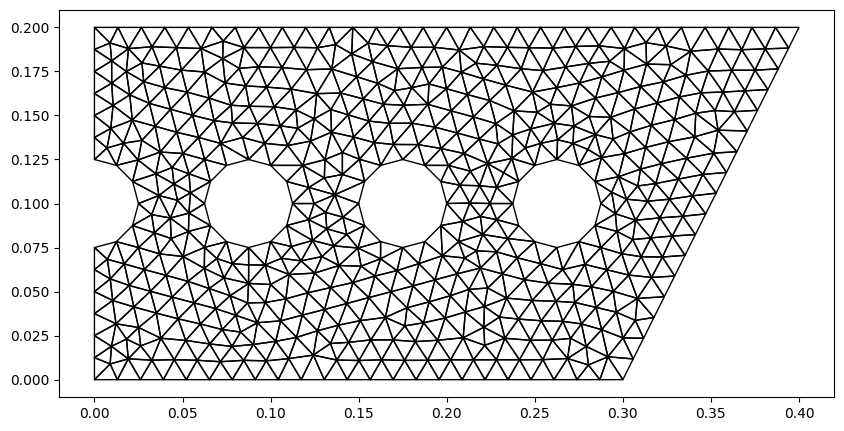

In [25]:
# Define surfaces
g.surface([0, 1, 2, 3, 4, 5, 6], [[7, 8, 9, 10], [11, 12, 13, 14], [15, 16, 17, 18]])

# Create mesh
mesh = cfm.GmshMesh(g)
# set size factor of elements
mesh.el_size_factor = 0.03
# Triangular elements
mesh.el_type = 2
# Only temperature, so one D.O.F. per node
mesh.dofs_per_node = 1
# Return dictionary with elements on boundary
mesh.return_boundary_elements = True
# Get coordinates, D.O.F.s of elements, D.O.F.s, D.O.F.s on boundary
# and boundary elements
coords, edof, dofs, bdofs, elementmarkers, boundary_elements = mesh.create()
# Extract x- and y-coordinates of each element
ex, ey = cfc.coordxtr(edof, coords, dofs, 3)

# Draw mesh
cfv.figure(fig_size=(10,10))
cfv.draw_mesh(coords, edof, dofs_per_node=mesh.dofs_per_node, el_type=mesh.el_type)

# Formulate Heat Flow Problem

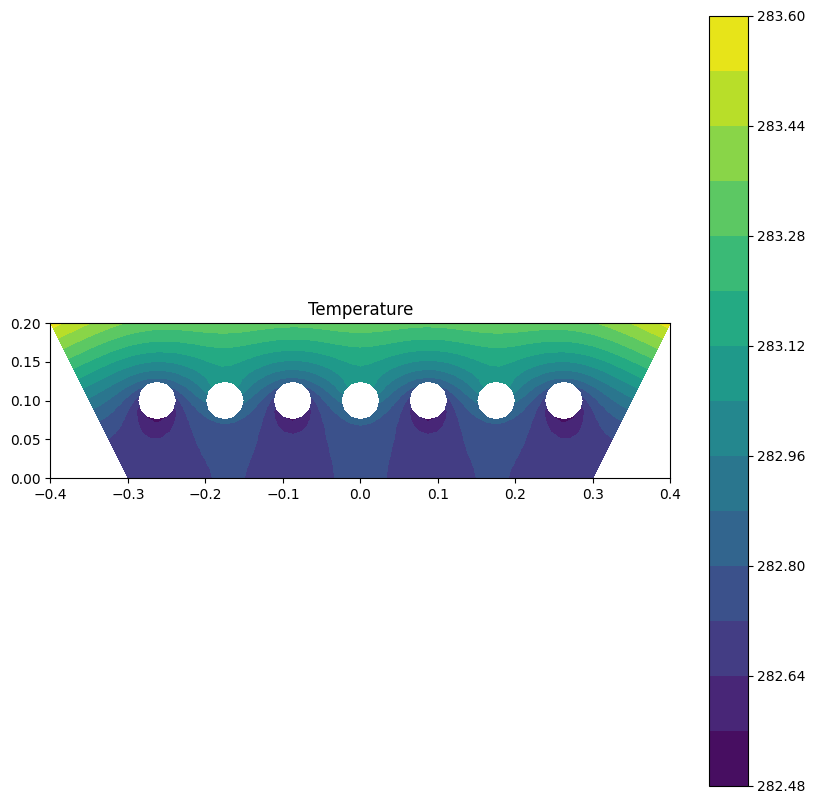

In [26]:
# Extract number of D.O.F.s and number of elements 
NDOF = len(dofs)
NELEM = len(edof)

# Define stiffness matrix
K = np.zeros((NDOF, NDOF))

# Compute stiffness matrix
for i in range(NELEM):
    kei = cfc.flw2te(ex[i, :], ey[i, :], [1], np.eye(2) * k)
    K = cfc.assem(edof[i, :], K, kei)

# Convection boundary effect
fb = np.zeros((NDOF, 1))

# Function for handling convective boundary conditions
def convection(MARKER, K, fb, T_inf, alpha):
    """
    Function for adding the contribution of convective boundary condition  
    on boundary marker proportionality constant alpha and surrounding 
    temperature T_inf to the stiffness matrix and boundary load vector.

    Inputs:
        MARKER: marker of boundary
        K: Stiffness matrix
        fb: Boundary load vector
        T_inf: surrounding temperature at bondary
        alpha: Newton convection constant
        
    Outputs:
        NONE
    """
    # Extract all D.O.F pairs on boundary i.e. for all elements with two D.O.F. on boundary MARKER,
    # get the pair
    boundary_pairs = [belem['node-number-list'] for belem in boundary_elements[MARKER]]

    for pair in boundary_pairs:
        # Extraxt indices of D.O.F.s
        # Do not forget the -1 to go from dof to index in the list
        index1 = pair[0]-1
        index2 = pair[1]-1

        # Compute lenght L of curve on boundary (line from coords[index1] to coords[index2]) 
        l = np.linalg.norm(coords[index1] - coords[index2])

        # Integral of formfunction N_i squared over intervall
        area_squared = l/3
        # Area of cross term between the two form functions
        area_cross = l/6 

        # Add the subsystem with a term to the stiffness matrix K
        K[index1, index1] += area_squared * alpha
        K[index2, index2] += area_squared * alpha
        K[index1, index2] += area_cross * alpha
        K[index2, index1] += area_cross * alpha

        # Area of of the formfunction between two dofs
        area = l/2

        # Add subsytem to Fb vector
        fb[index1] += area*alpha*T_inf
        fb[index2] += area*alpha*T_inf

# Calculate the convection effect for top boundary with MARKER_CONVECTION
# and all the circles respectively using previous marking
convection(MARKER_CONVECTION, K, fb, T0, alpha_n)
convection(MARKER_CIRCLE, K, fb, T_out, alpha_c)
convection(MARKER_CIRCLE + 1, K, fb, T_in, alpha_c)
convection(MARKER_CIRCLE + 2, K, fb, T_out, alpha_c)
convection(MARKER_CIRCLE + 3, K, fb, T_in, alpha_c)

# Boundary conditions
bc, bc_value = np.array([], 'i'), np.array([], 'f')

# Solve BVP
a, r = cfc.solveq(K, fb,  bc, bc_value)

# Draw color plot of stationary temperature
cfv.figure(fig_size=(10,10))
cfv.draw_nodal_values_contourf(a, coords, edof, title="Temperature", levels=12)

# Draw other half of battery thanks to symmetry
cfv.draw_nodal_values_contourf(a, np.array([[-coord[0], coord[1]] for coord in coords]), edof)
cfv.colorbar()

## Transient Heat Flow

In [27]:
# Package for solving ivp
from scipy.integrate import solve_ivp
# Package given for calculating C matrix in task
from plantml import plantml

In [28]:
# First model of effectFactor 1000 due to kW/m^3 given in task
def Q_1(t):
    """
    Time function for first model of generated heat

    Inputs:
        t: current time

    Outputs:
        Heat generated at time t [J/m^3]
    """
    if t < 0:
        return 0
    return 100*np.e**(-144*((600 - t)/3600)**2) * 1000

# Second model of effect. Factor 1000 due to kW/m^3 given in task
def Q_2(t):
    """
    Time function for second model of generated heat

    Inputs:
        t: current time

    Outputs:
        Heat generated at time t [J/m^3]
    """
    if t < 0 or 600 < t:
        return 0
    return 88.42 * 1000

In [29]:
# Redefine stiffness matrix K and natural boundary condition 
# load vector fl, also define boundary vector fb
K = np.zeros((NDOF, NDOF))
fl = np.zeros((NDOF,1))
fb = np.zeros((NDOF,1))
# Create the C matrix
C = np.zeros_like(K)

# Compute stiffness matrix and natural boundary condition
for i in range(NELEM):
    # Heat suplly per unit volume is set to unit as Q not dependent on geometry 
    # and can be multiplied in later
    kei, fle = cfc.flw2te(ex[i, :], ey[i, :], [1], np.eye(2) * k, eq=1)
    K, fl = cfc.assem(edof[i, :], K, kei, fl, fle)

    # Use given plantml function to create C subsystem
    Ce = plantml(ex[i], ey[i], density * specific_heat)

    # Add respective component of submatrix to larger C matrix
    C = cfc.assem(edof[i, :], C, Ce)

# Again, since K is reconstructed, calculate the convection 
# effect for top boundary with MARKER_CONVECTION
# and all the circles respectively using previous marking
convection(MARKER_CONVECTION, K, fb, T0, alpha_n)
convection(MARKER_CIRCLE, K, fb, T_out, alpha_c)
convection(MARKER_CIRCLE + 1, K, fb, T_in, alpha_c)
convection(MARKER_CIRCLE + 2, K, fb, T_out, alpha_c)
convection(MARKER_CIRCLE + 3, K, fb, T_in, alpha_c)

\begin{align*}
    \frac{\partial\mathbf{a}}{\partial t}&=-\mathbf{C}^{-1}\mathbf{Ka}+\mathbf{C}^{-1}\mathbf{f}_b+\mathbf{C}^{-1}\mathbf{f}_b=:\\
    &=: \mathbf{CK}\mathbf{a}+\mathbf{CFb}+\mathbf{CFl}
\end{align*}

In [30]:
#Define matrices presented in markdown above
C_inv = np.linalg.inv(C)

CK = -1*C_inv@K
CFb = C_inv@fb.flatten()
CFl = C_inv@fl.flatten()

Solving ivp for
\begin{equation*}
    Q = f_1(t)
\end{equation*} 

In [31]:
# IVP_problem for Q = f_1
def IVP_function_for_f_1(t, a):
    return CK @ a + CFb + CFl * Q_1(t)

# Initial value
a0 = np.full((NDOF,), T0)

# timesteps for which the temperature is to be evaluated
nbr_steps = 3600
time_steps = np.linspace(0,3600,nbr_steps)

# Solving IVP with scipy.integrate implicit solver for bot
solution_Q1 = solve_ivp(IVP_function_for_f_1, (0,3600), a0, method='Radau', t_eval=time_steps)

Solving IVP for
\begin{equation*}
    Q = f_2(t)
\end{equation*}

In [32]:
# IVP_problem for Q = f_2
def IVP_function_for_f_2(t, a):
    return CK @ a + CFb + CFl * Q_2(t)

# Note, same initial value and timesteps

# Solving IVP with scipy.integrate implicit solver for bot
solution_Q2 = solve_ivp(IVP_function_for_f_2, (0,3600), a0, method='Radau', t_eval=time_steps)

In [33]:
def extr_max_min(solution, plot_max_and_min=False):
    """
    Function for extracting total max and min temperature of distribution and 
    optionally plot max and min of all nodes for a given time over time

    Inputs: 
        solution: solution from scipy.integrate.solve_ivp
        plot_max_and_min: boolean determining if plot is done

    Outputs:
        total_max: global max temperature
        index_for_max_temp: index in solution where temperature 
                            is maximal
        total_min: global min temperature
        index_for_min_temp: index in solution where temperature 
                            is minimal

    """
    maxTemps = []
    minTemps = []
    total_max = -1
    total_min = 1000
    index_for_max_temp = 0
    index_for_min_temp = 0

    for n in range(nbr_steps - 1):
        curr_sol = solution.y[:,n]
        current_max = np.max(curr_sol)
        current_min = np.min(curr_sol)
        
        if total_max < current_max:
            total_max = current_max
            index_for_max_temp = n
        
        if current_min < total_min:
            total_min = current_min
            index_for_min_temp = n

        maxTemps.append(current_max)
        minTemps.append(current_min)

    maxTemps.append(np.max(curr_sol))
    minTemps.append(np.min(curr_sol))

    if total_max < maxTemps[-1]:
        total_max = maxTemps[-1]
        index_for_max_temp = -1
            
    if minTemps[-1] < total_min:
        total_min = minTemps[-1]
        index_for_min_temp = -1

    if plot_max_and_min:
        plt.plot(solution.t, maxTemps, label='Max temperature')
        plt.plot(solution.t, minTemps, label='Min temperature')
        plt.axhline(y = T0, label='Initial temperature', linestyle='--')
        plt.legend()
        plt.title('Extreme Values for Temperature Over Time')
        plt.xlabel('t [s]')
        plt.ylabel('T [K]')    
        
    return total_max, index_for_max_temp, total_min, index_for_min_temp

In [34]:
# Function for plotting temperature distribution 
def plot_temp_distribution_for_time_t(solution, t):
    """
    Uses calfem.vis_mpl to visualize temperature distribution
    for solution and time in range [0, 3600)

    Inputs: 
        solution: solution object from scipy.integrate.solve_ivp
        t: time of evaluation

    Outputs:
        NONE
    """
    if 0 <= t and t < 3600:
        cfv.figure(fig_size=(10, 10))
        cfv.draw_nodal_values_contourf(solution.y[:, t], coords, edof)
        # Draw other half of battery thanks to symmetry
        cfv.draw_nodal_values_contourf(a, np.array([[-coord[0], coord[1]] for coord in coords]), edof)
        cfv.colorbar()

Plot of maximum and minimum temperature for solution to $Q=f_1$. As is visible, the maximum deviation of $T_0=293$ is larger for maximum temperature than for minimum, why this is used for calculating von Mises stress.

(310.56104899054196, 925, 287.4049725333743, 3598)

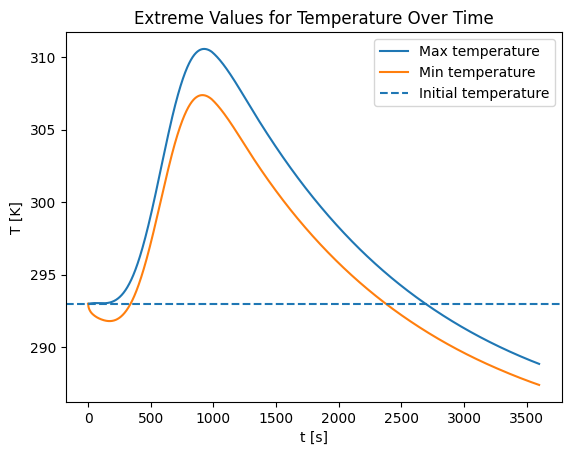

In [35]:
extr_max_min(solution_Q1, True)

Plot of maximum and minimum temperature for solution to $Q=f_2$. Again, it is visible that the maximum deviation of $T_0=293$ is larger for maximum temperature than for minimum, why this is used for calculating von Mises stress.

(313.992334461981, 601, 286.7331695264372, 3598)

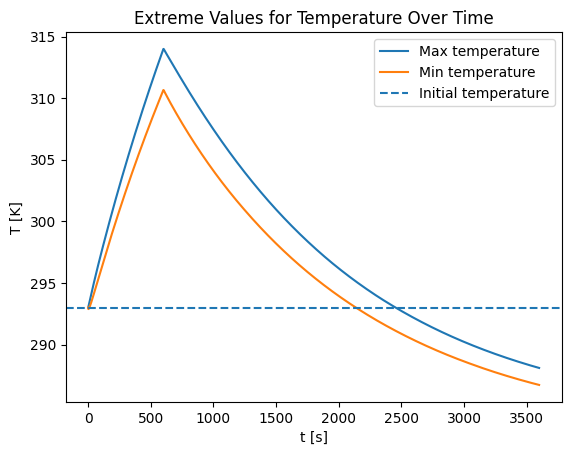

In [36]:
extr_max_min(solution_Q2, True)

## Stesses and Strains

## Redefine geometry with new markers (Basically same code as before)

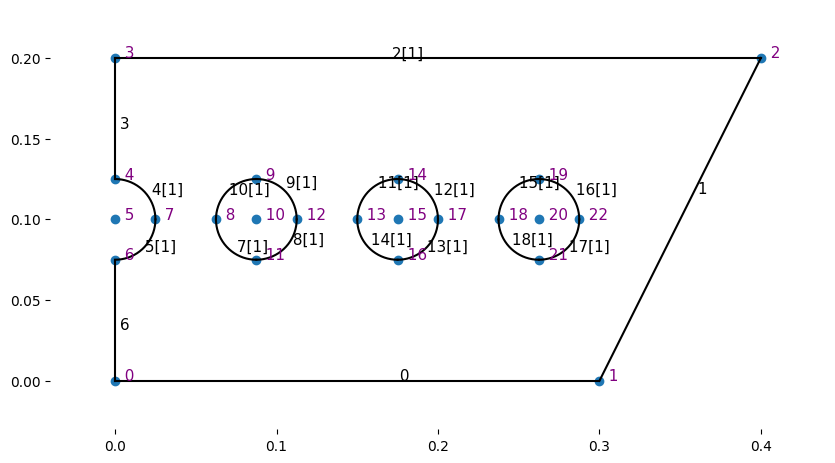

In [37]:
# Create geometry tool
g = cfg.geometry()

# Define points
points = [
    [0, 0], [L1, 0], [L2, H], [0, H],                                           # Points on outer parallellipiped 0, 1, 2, 3
    [0, H/2 + R], [0, H/2], [0, H/2 - R], [R, H/2],                             # Points on half circle 4, 5, 6, 7
    [D - R, H/2], [D, H/2 + R], [D, H/2], [D, H/2 - R], [D + R, H/2],           # Points on circle center in D, H/2 8, 9, 10, 11, 12
    [2*D - R, H/2], [2*D, H/2 + R], [2*D, H/2], [2*D, H/2 - R], [2*D + R, H/2], # Points on circle center in 2D, H/2 13, 14, 15, 16, 17 
    [3*D - R, H/2], [3*D, H/2 + R], [3*D, H/2], [3*D, H/2 - R], [3*D + R, H/2]  # Points on circle center in 3D, H/2 18, 19, 20, 21, 22
]

# Add points in cfg.geometry()
for index, point in enumerate(points):
    g.point(point, index)

# Markers for boundary conditions
MARKER_u_0 = 0
MARKER_t_0 = 1

# Define lines
g.spline([0, 1], 0, MARKER_u_0)
g.spline([1, 2], 1, MARKER_u_0)
g.spline([2, 3], 2, MARKER_t_0)
g.spline([3, 4], 3, MARKER_u_0)
g.spline([6, 0], 6, MARKER_u_0)

# Define circlearcs i.e. the 14 quartercircles of the battery geometry
circlearcs = [
    [4, 5, 7], [7, 5, 6],                                   
    [8, 10, 11], [11, 10, 12], [12, 10, 9], [9, 10, 8],    
    [13, 15, 14], [14, 15, 17], [17, 15, 16], [16, 15, 13],
    [18, 20, 19], [19, 20, 22], [22, 20, 21], [21, 20, 18]    
] 

# Define circles
for index, circlearc in enumerate(circlearcs):
    offset = 4 if index < 2 else 5
    g.circle(circlearc, index + offset, MARKER_t_0)

# Draw geometry
cfv.figure(fig_size=(10,10))
cfv.draw_geometry(g, draw_points=True, label_curves=True, label_points=True)

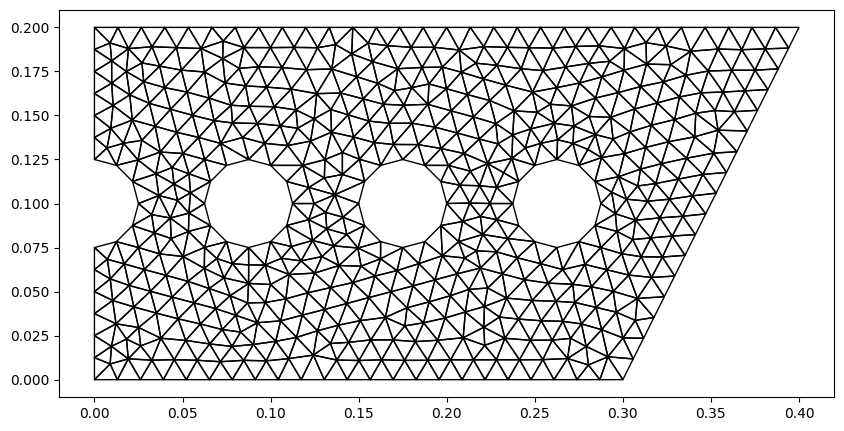

In [38]:
# Define surfaces
g.surface([0, 1, 2, 3, 4, 5, 6], [[7, 8, 9, 10], [11, 12, 13, 14], [15, 16, 17, 18]])

# Create mesh
mesh = cfm.GmshMesh(g)
mesh.el_size_factor = 0.03
mesh.el_type = 2
mesh.dofs_per_node = 2
mesh.return_boundary_elements = True
coords, edof, dofs, bdofs, elementmarkers, boundary_elements = mesh.create()
ex, ey = cfc.coordxtr(edof, coords, dofs, 3)

# Draw mesh
cfv.figure(fig_size=(10,10))
cfv.draw_mesh(coords, edof, dofs_per_node=mesh.dofs_per_node, el_type=mesh.el_type)

## FE formulation of stresses and strains

In [39]:
G = E /(1 - 2*v)
ptype = 1
ep = [ptype,thickness]

D = cfc.hooke(ptype, E, v)

NELEM = len(edof)
NDOF =  2 * len(dofs)

def C_matrix_inv(x1, y1, x2, y2, x3, y3):
    """
    Returns the inverse of coordinate matrix of an element

    Input:
        x1, y1: coordinates of the first node
        x2, y2: coordinates of the second node
        x3, y3: coordinates of the third node

    Output: 
        C_inv: inverse of coordinate matrix
        detC: determinant of coordinate matrix
    """
    C = np.mat([
        [1, x1, y1, 0, 0, 0],
        [0, 0, 0, 1, x1, y1],
        [1, x2, y2, 0, 0, 0],
        [0, 0, 0, 1, x2, y2],
        [1, x3, y3, 0, 0, 0],
        [0, 0, 0, 1, x3, y3]
    ])
    return np.linalg.inv(C), np.linalg.det(C)
    
def FE_form_stresses_and_strains(T):
    """
    Function for setting up the FE-formulation stiffness matrix
    and temperature strain matrix and given temperature distribution.

    Inputs:
        T: temperature distribution vector of dimension (NDOF, 1)

    Outputs:
        K: Stiffness matrix for system
        f0: temperature contribution load 
            vector

    """

    # Define K matrix and f0
    K = np.zeros((NDOF, NDOF))
    f0 = np.zeros((NDOF, 1))

    B_matrix = np.mat([
        [0, 1, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1],
        [0, 0, 1, 0, 1, 0]
    ])

    T = np.repeat(T, 2)
    for el_nodes, elx_coords, ely_coords in zip(edof, ex, ey):
        Ke = cfc.plante(elx_coords, ely_coords, ep, D)
        cfc.assem(el_nodes, K, Ke)

        D_eps0 = G * alpha * np.array([
            [T[el_nodes[0] - 1] - 293],
            [T[el_nodes[2] - 1] - 293],
            [T[el_nodes[4] - 1] - 293]
        ])

        C_mat_inv, double_area = C_matrix_inv(elx_coords[0], ely_coords[0], 
                                        elx_coords[1], ely_coords[1], 
                                        elx_coords[2], ely_coords[2])

        f0e = double_area/2 * C_mat_inv.T @ B_matrix.T @ D_eps0
        
        # For loop designed by Emil Svensson: certified cool guy
        # who saved us 4 lines 
        for i in range(6):
            f0[el_nodes[i] - 1] += f0e[i, 0] 

    return K, f0

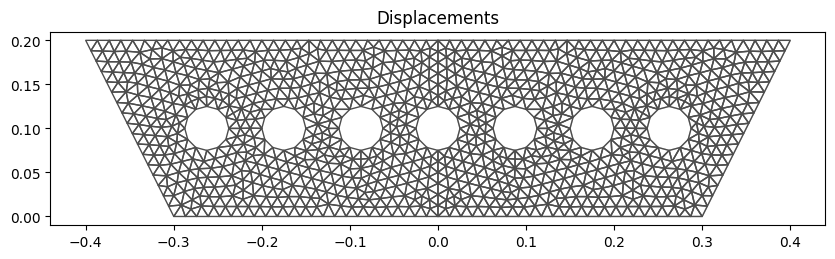

In [42]:
_, max_index, _, _  = extr_max_min(solution_Q1, plot_max_and_min=False)

K, f0 = FE_form_stresses_and_strains(solution_Q1.y[:,index])
bc, bc_value = np.array([], 'i'), np.array([], 'f')
bc, bc_value = cfu.applybc(bdofs, bc, bc_value, MARKER_u_0, 0.0, 0)

# Solve BVP
u, r = cfc.solveq(K, f0,  bc, bc_value)
cfv.figure(fig_size=(10,10))
cfv.draw_displacements(u, coords, edof, mesh.dofs_per_node, mesh.el_type, draw_undisplaced_mesh=True, title="Displacements")
cfv.draw_displacements(u, np.array([[-coord[0], coord[1]] for coord in coords]), edof, mesh.dofs_per_node, mesh.el_type)


In [49]:
def calculate_von_mises(displacement_vector):
    
    von_mises = []
    
    def sigma_zz(sigma_xx, sigma_yy, dT):
        return v*(sigma_xx + sigma_yy) - alpha * dT

    def von_mises(sigma_xx, sigma_yy, sigma_zz, sigma_xy):
        np.sqrt(sigma_xx**2 + sigma_yy**2 + sigma_zz**2 
                - sigma_xx*sigma_yy - sigma_xx*sigma_zz - sigma_yy*sigma_zz + 
                3*sigma_xy**2)

    for el_dofs, el_x, el_y, coord in zip(edof, ex, ey, coords):
        

SyntaxError: incomplete input (1356847694.py, line 14)

In [50]:
ex

array([[0.15      , 0.15334936, 0.13650767],
       [0.15334936, 0.14075902, 0.13650767],
       [0.19665064, 0.1875    , 0.19749824],
       ...,
       [0.21343322, 0.20749903, 0.2186381 ],
       [0.12165064, 0.13125   , 0.12471179],
       [0.21014408, 0.21915122, 0.21695942]])

In [53]:
ey

array([[0.1       , 0.1125    , 0.10498476],
       [0.1125    , 0.11647837, 0.10498476],
       [0.0875    , 0.07834936, 0.07038234],
       ...,
       [0.1183561 , 0.11039093, 0.11009721],
       [0.09084936, 0.09497563, 0.09999208],
       [0.06908166, 0.06339262, 0.07316335]])

In [47]:
edof

array([[  23,   24,  217,  218,  767,  768],
       [ 217,  218,  533,  534,  767,  768],
       [ 225,  226,  227,  228,  769,  770],
       ...,
       [ 943,  944,  569,  570,  997,  998],
       [ 571,  572,  923,  924, 1049, 1050],
       [ 937,  938,  765,  766, 1065, 1066]], dtype=int32)

In [52]:
dofs

array([[   1,    2],
       [   3,    4],
       [   5,    6],
       ...,
       [1061, 1062],
       [1063, 1064],
       [1065, 1066]])

In [48]:
coords

array([[0.        , 0.        ],
       [0.3       , 0.        ],
       [0.4       , 0.2       ],
       ...,
       [0.04514137, 0.11109754],
       [0.07308501, 0.19223115],
       [0.21695942, 0.07316335]])